
<img src="../../images/brownbear.png" width="400">

## A financial tool that can analyze and maximize investment portfolios on a risk adjusted basis  


Description: This notebook is useful for examining potfolios comprised of stocks from the S&P 400.  Construct portfolios from the 400 stocks in the S&P 400 mid cap index and examine the results of different weighting schemes.


In [1]:
%%javascript
IPython.OutputArea.prototype._should_scroll = function(lines) {
    return false;
}

<IPython.core.display.Javascript object>

In [2]:
# imports
import pandas as pd
import matplotlib.pyplot as plt
import brownbear as bb

# format price data
pd.options.display.float_format = '{:0.2f}'.format

# display all rows
pd.set_option('display.max_rows', None)

# do not truncate column names
pd.set_option('display.max_colwidth', None)

%matplotlib inline

In [3]:
# set size of inline plots
'''note: rcParams can't be in same cell as import matplotlib
   or %matplotlib inline
   
   %matplotlib notebook: will lead to interactive plots embedded within
   the notebook, you can zoom and resize the figure
   
   %matplotlib inline: only draw static images in the notebook
'''
plt.rcParams["figure.figsize"] = (10, 7)

### Some Globals

In [4]:
investment_universe = ['sp400-galaxy']

In [5]:
# Fetch Investment Options - all values annualized
df = bb.fetch(investment_universe, risk_free_rate=0, annual_returns='3 Yr')
df

,Investment Option,Description,Asset Class,3 mo,6 mo,1 Yr,1-1 Yr,3 Yr,5 Yr,Vola,DS Vola,SD 1 Yr,SD 3 Yr,SD 5 Yr,Annual Returns,Std Dev,Sharpe Ratio
0,AA,Alcoa,US Stocks:Materials,-29.32,0.05,80.33,93.85,18.34,11.16,65.67,45.01,48.24,49.84,54.01,18.34,49.84,0.37
1,AAL,American Airlines Group,US Stocks:Industrials,816.23,30.61,61.01,61.57,3.08,-4.41,53.41,21.33,48.51,44.66,42.67,3.08,44.66,0.07
2,AAON,AAON,US Stocks:Industrials,468.18,176.19,74.23,75.01,25.23,25.29,55.93,37.33,62.58,54.43,48.04,25.23,54.43,0.46
3,ACI,Albertsons,US Stocks:Consumer Staples,-59.62,-36.89,-34.01,-33.92,-12.12,0.19,38.28,29.01,21.19,17.81,27.98,-12.12,17.81,-215.86
4,ACM,AECOM,US Stocks:Industrials,-54.92,-48.08,-37.13,-35.34,-5.62,3.57,28.64,16.47,33.20,28.09,26.21,-5.62,28.09,-157.87
5,ADC,Agree Realty,US Stocks:Real Estate,19.19,17.78,9.95,9.65,10.38,6.26,18.63,10.56,15.68,17.36,18.14,10.38,17.36,0.60
6,AEIS,Advanced Energy,US Stocks:Technology,57.73,157.17,160.58,161.65,49.23,27.51,76.01,42.20,46.40,39.86,37.98,49.23,39.86,1.24
7,AFG,American Financial Group,US Stocks:Financials,57.20,7.92,18.46,19.48,12.57,11.41,18.77,7.84,18.98,19.49,20.87,12.57,19.49,0.64
8,AGCO,AGCO,US Stocks:Industrials,23.10,29.56,17.46,17.95,-1.94,2.10,36.08,18.31,33.12,28.06,33.03,-1.94,28.06,-54.44
9,AHR,American Healthcare REIT,US Stocks:Real Estate,51.39,17.90,47.23,44.40,47.23,47.23,29.18,17.35,24.35,30.24,30.24,47.23,30.24,1.56


In [6]:
# Rank
rank = bb.rank(df, rank_by='Sharpe Ratio', group_by='Asset Subclass', num_per_group=1)
rank_filtered = rank
#rank_filtered = rank.loc[(rank['3 mo'] > 0) & rank['1 Yr'] > 0]
rank_filtered = rank_filtered.head(20)
rank_filtered

,Investment Option,Description,Asset Class,3 mo,6 mo,1 Yr,1-1 Yr,3 Yr,5 Yr,Vola,DS Vola,SD 1 Yr,SD 3 Yr,SD 5 Yr,Annual Returns,Std Dev,Sharpe Ratio
346,TLN,Talen Energy,US Stocks:Utilities,129.24,8.39,37.05,40.31,104.78,104.78,58.25,30.31,39.55,35.09,35.09,104.78,35.09,2.99
354,TTMI,TTM Technologies,US Stocks:Technology,1365.68,562.22,368.64,388.49,137.81,66.91,78.46,43.66,68.14,61.55,54.49,137.81,61.55,2.24
93,CTRE,CareTrust REIT,US Stocks:Real Estate,47.31,24.81,37.92,39.37,34.04,17.41,30.42,18.02,17.58,19.03,24.85,34.04,19.03,1.79
65,CDE,Coeur Mining,US Stocks:Materials,-17.04,-23.73,80.64,81.43,78.39,12.06,76.02,51.39,79.98,68.36,62.81,78.39,68.36,1.15
90,CRS,Carpenter Technology,US Stocks:Industrials,573.99,230.17,122.67,124.76,128.09,74.00,36.69,8.91,43.97,44.27,47.47,128.09,44.27,2.89
53,BTSG,BrightSpring Health Services,US Stocks:Healthcare,605.18,234.25,198.87,205.09,198.87,198.87,35.86,21.38,35.26,50.19,50.19,198.87,50.19,3.96
391,WTFC,Wintrust Financial,US Stocks:Financials,119.90,26.33,31.08,34.97,35.04,17.80,23.28,11.30,14.51,23.44,25.69,35.04,23.44,1.49
110,DTM,DT Midstream,US Stocks:Energy,45.52,54.31,38.28,45.00,51.37,51.37,16.69,7.77,21.54,20.02,22.28,51.37,20.02,2.57
364,USFD,US Foods,US Stocks:Consumer Staples,61.58,79.93,33.54,29.03,34.21,22.37,24.73,8.01,36.08,28.27,29.31,34.21,28.27,1.21
156,GHC,Graham Holdings,US Stocks:Consumer Discretionary,46.51,8.96,20.27,23.61,27.31,13.48,24.83,16.60,26.37,22.04,21.88,27.31,22.04,1.24


### Sample Portfolios
Format 'Investment option': weight

In [7]:
# everything ranked
ranked_portfolio = {
    'Title': 'Ranked Portfolio'
}
everything = list(rank_filtered['Investment Option'])
ranked_portfolio.update(dict.fromkeys(everything, 1/len(everything)))

# top 10
top10_portfolio = {
    'Title': 'Ranked Portfolio'
}
top10 = list(rank_filtered['Investment Option'])[:10]
top10_portfolio.update(dict.fromkeys(top10, 1/len(top10)))

### Custom Portfolios

In [8]:
# My portfolio
my_portfolio = {
    'Title': 'My Portfolio',

}

### Choose Portfolio Option

In [9]:
# Select one of the portfolios from above
portfolio_option = ranked_portfolio

In [10]:
# Make a copy so that the original portfolio is preserved
portfolio_option = portfolio_option.copy()

### Analysis Options

In [11]:
# Specify the weighting scheme.  It will replace the weights specified in the portfolio
# You can also fix the weights on some Investent Options, Asset Classes, and Asset Subclasses
# while the others are automatically calculated.

# 'Equal' - will use equal weights.

# 'Sharpe Ratio' - will use proportionally weighted # allocations based on the percent
#  of an investment option's sharpe ratio to the sum of all the sharpe ratios in the portfolio.

# 'Std Dev' - will use standard deviation adjusted weights

# 'Annual Returns' - will use return adjusted weights

# 'Vola' - will use volatility adjusted weights

# 'DS Vola' - will use downside volatility adjusted weights

# None: 'Investment Option' means use user specified weights
#       'Asset Class' means do not group by Asset Class
#       'Asset Subclass means do not group by Asset Subclass 

weight_by = {
    'Asset Class':       {'weight_by': None},
    'Asset Subclass':    {'weight_by': None},
    'Investment Option': {'weight_by': 'DS Vola'},
}
#weight_by = None

In [12]:
bb.DEBUG = False

# Analyze portfolio
annual_ret, std_dev, sharpe_ratio = \
    bb.analyze(df, portfolio_option, weight_by)

,TLN,TTMI,CTRE,CDE,CRS,BTSG,WTFC,DTM,USFD,GHC,NYT,Ranked Portfolio
Annual Returns,104.78,137.81,34.04,78.39,128.09,198.87,35.04,51.37,34.21,27.31,24.76,68.76
Std Dev,35.09,61.55,19.03,68.36,44.27,50.19,23.44,20.02,28.27,22.04,24.77,18.92
Sharpe Ratio,2.99,2.24,1.79,1.15,2.89,3.96,1.49,2.57,1.21,1.24,1.00,3.63
Weight,0.05,0.03,0.08,0.03,0.15,0.07,0.13,0.15,0.15,0.09,0.08,1.00
Worst Typical Down Year,34.60,14.71,-4.02,-58.33,39.55,98.49,-11.84,11.33,-22.33,-16.77,-24.78,30.93
Black Swan,-0.49,-46.84,-23.05,-126.69,-4.72,48.30,-35.28,-8.69,-50.60,-38.81,-49.55,12.01


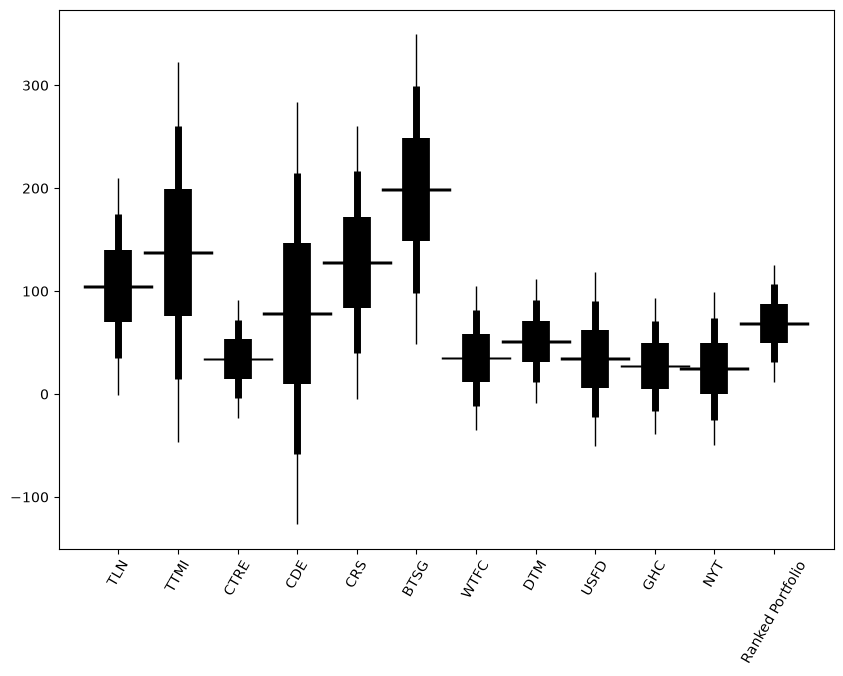

In [13]:
# Display Results
summary = bb.summary(df, portfolio_option, annual_ret, std_dev, sharpe_ratio)
summary

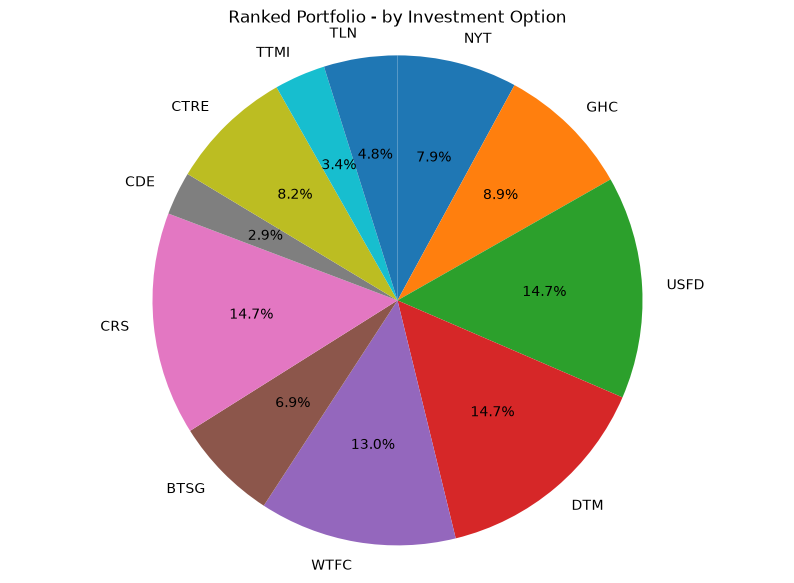

NYT    0.08
GHC    0.09
USFD   0.15
DTM    0.15
WTFC   0.13
BTSG   0.07
CRS    0.15
CDE    0.03
CTRE   0.08
TTMI   0.03
TLN    0.05



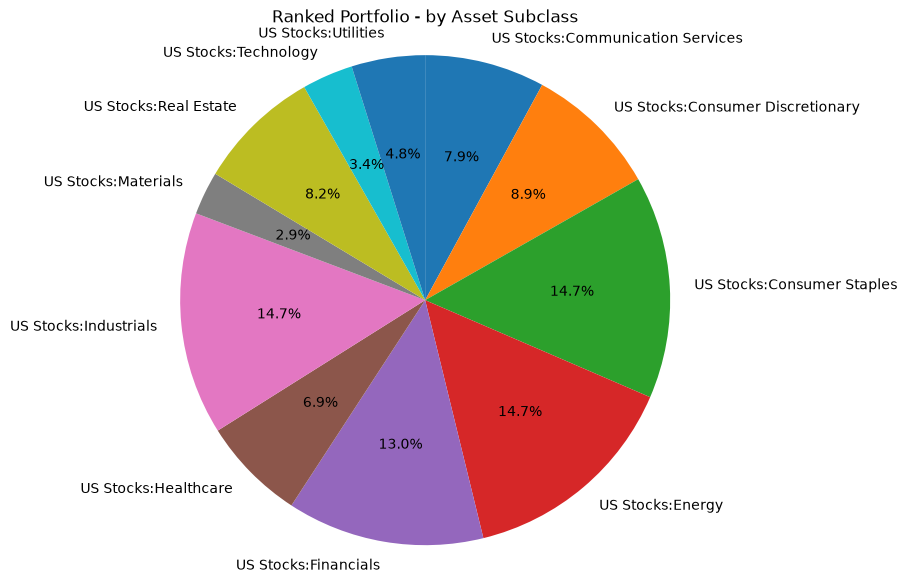

US Stocks:Communication Services   0.08
US Stocks:Consumer Discretionary   0.09
US Stocks:Consumer Staples         0.15
US Stocks:Energy                   0.15
US Stocks:Financials               0.13
US Stocks:Healthcare               0.07
US Stocks:Industrials              0.15
US Stocks:Materials                0.03
US Stocks:Real Estate              0.08
US Stocks:Technology               0.03
US Stocks:Utilities                0.05



In [14]:
# Show pie charts of investment and asset class weights
bb.show_pie_charts(df, portfolio_option, charts=['Investment Option', 'Asset Subclass'])

In [15]:
# Show exact weights
bb.print_portfolio(portfolio_option)

Ranked Portfolio Weights:
    TLN                            0.0485
    TTMI                           0.0337
    CTRE                           0.0816
    CDE                            0.0286
    CRS                            0.1470
    BTSG                           0.0688
    WTFC                           0.1301
    DTM                            0.1470
    USFD                           0.1470
    GHC                            0.0886
    NYT                            0.0792


### Optimize Portfolio

In [16]:
# Run_portfolio_optimizer = True will run portfolio optimizer after portfolio analysis is complete
run_portfolio_optimizer = False

In [17]:
# Optimize sharpe ratio while specifying Annual Rate, Worst Typical Down Year,
# and Black Swan.  Setting a constraint to None optimizes absolute Sharpe Ratio
# without regard to that constraint.

'''
constraints = {
    'Annual Return': 12,
    'Worst Typical Down Year': -5,
    'Black Swan': None
}
'''

constraints = {
    'Annual Return': 8,
    'Worst Typical Down Year': None,
    'Black Swan': -40
}

if run_portfolio_optimizer:
    bb.optimizer(df, portfolio_option, constraints)

### Use Sharpe Ratio adjusted weights
Recommend that you also try using Sharpe Ratio adjusted weights and compare those results with the Optimized Portflio.  
It tends to produce a higher Annual Return while keeping the allocations more balanced than the Optimizer.  (See 'Analysis Options' section).